# NLP MIDTERM PROJECT: AUTHOR DETECTION USING NLP

**SERHAT TAY / 220709054**


---
**# Project: Who Wrote This? Authorship Attribution using NLP**
**Objective**

The goal is to build a machine learning model that can identify the author of a given text based on their writing style. We will use the 30Columnist dataset, preprocess the text, extract TF-IDF features, and train a classifier.



---




Explanation
 ---
 Author detection is a classification task where every author is represented as
and differentiated by the vocabulary they used. Since stopwords are words that are supposed to be common for every and each text, it is expected that stopwords are not specific enough to differentiate authors from each other.




---


# Informations about the dataset used in this project:
***Dataset: 30Columnists.zip***
---

**Content**: 1,500 English articles from 30 distinct authors (50 articles per author).

**Primary Source**: The Raw_texts folder inside the archive.

**Target Structure:** Data should be loaded into a dictionary: dataset: {author: [docs]}.

**Origin:** Created by Yurdacan & Amasyali (Yildiz Technical Univ., 2010).



---



# Task
Perform a comprehensive authorial style analysis and text generation task using the `30Columnists.zip` dataset. This involves loading and inspecting the dataset, performing detailed text cleaning and preprocessing (including tokenization with special handling for "word.word" issues, punctuation removal, case folding, and stopword removal, with optional stemming/lemmatization), and then building and evaluating both N-gram language models (unigram, bigram, and trigram) and a Transformer-based text generation model. For the N-gram models, estimate probabilities, implement perplexity for evaluation, and generate text samples. For author attribution, extract TF-IDF features (word and character n-grams), train and evaluate a classification model (using accuracy, F1-score, and a confusion matrix), and analyze top indicative features for each author. Finally, summarize and compare the performance and insights from all models.



---


# PART A - DATA PREPERATION


---
***PART A.1 - Load the dataset and inspect its structure***


**Loading the dataset and inspect its structure is the first task of data preperation.**



---
First of all, we need to download our dataset from the given resource link for 30Columnist dataset. After the download is finished then the next step is to unzip it.

In [1]:
#this is where we download the dataset
!gdown https://drive.google.com/uc?id=120-9PFzIvWy1SVHpTiOO6_7vOyMpXZEy

Downloading...
From (original): https://drive.google.com/uc?id=120-9PFzIvWy1SVHpTiOO6_7vOyMpXZEy
From (redirected): https://drive.google.com/uc?id=120-9PFzIvWy1SVHpTiOO6_7vOyMpXZEy&confirm=t&uuid=008af3c7-c153-447e-8425-9e2b65a2a348
To: /content/30Columnists.zip
100% 7.38M/7.38M [00:00<00:00, 32.1MB/s]


In [2]:
# Plus this is where we unzip the content as below
!unzip /content/30Columnists.zip -d /content

Archive:  /content/30Columnists.zip
  inflating: /content/30Columnists/~$kubeni.doc  
  inflating: /content/30Columnists/~$readme.doc  
  inflating: /content/30Columnists/~WRL0001.tmp  
  inflating: /content/30Columnists/~WRL0003.tmp  
   creating: /content/30Columnists/arff_files/
  inflating: /content/30Columnists/arff_files/2gram.arff  
  inflating: /content/30Columnists/arff_files/LSI50.arff  
  inflating: /content/30Columnists/arff_files/numbers.arff  
  inflating: /content/30Columnists/arff_files/stanford_postagger_tags.arff  
  inflating: /content/30Columnists/arff_files/words_min50.arff  
  inflating: /content/30Columnists/arff_files/wordstems_min50.arff  
  inflating: /content/30Columnists/okubeni.doc  
   creating: /content/30Columnists/raw_texts/
   creating: /content/30Columnists/raw_texts/1/
  inflating: /content/30Columnists/raw_texts/1/1.1.txt  
  inflating: /content/30Columnists/raw_texts/1/1.10.txt  
  inflating: /content/30Columnists/raw_texts/1/1.11.txt  
  inflating

***First Task is done, here is the second task where we inspect its structure***


1.   Populate Authors List
2.   Read Articles for each Author  => dataset = {author:['article', 'article', ...], author:['article', 'article', ...], ...}
3.  Testing the previous steps



In [3]:
# Read sub-dirs as author names, i.e. labels
import os
data_path = "/content/30Columnists/raw_texts";

labels = [];
for author in os.listdir(data_path):
  labels.append(author);

labels.sort(key=lambda e : int(e));
print(labels)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30']


In [9]:
# Read articles of each author
import re
dataset = {}; # {author:[docs]}
for author in labels:
    docs = [];
    for file in os.listdir(os.path.join(data_path, author)):
      if file.endswith('.txt'):
        with open(os.path.join(data_path, author, file), 'rb') as f:
          # read the article line by line

          # "cp1254" solves \x92, \x93 etc issue
          article = f.read().decode('cp1254').replace('\n', '').replace('\r', '').replace('\f', '');
#          article = f.read().decode('iso-8859-9').replace('\n', '').replace('\r', '').replace('\f', '');
#          article = f.read().decode('cp1254');

          # make a basic cleaning, i.e., remove non printable chars like lf, cr, ff etc.
          article = re.sub(r"[\n\r\f]", "", article);
          docs.append(article);
#    print("# of files red for author {} is {}".format(author, len(docs)));
    dataset.update({author:docs});

# print the number of articles red for each author
for author in labels:
  print("{} \t {}".format(author, len(dataset[author])));

1 	 50
2 	 50
3 	 50
4 	 50
5 	 50
6 	 50
7 	 50
8 	 50
9 	 50
10 	 50
11 	 50
12 	 50
13 	 50
14 	 50
15 	 50
16 	 50
17 	 50
18 	 50
19 	 50
20 	 50
21 	 50
22 	 50
23 	 50
24 	 50
25 	 50
26 	 50
27 	 50
28 	 50
29 	 50
30 	 50


> In the following part we are going to test our last task, if it works or not, while collecting datas from each author to create a table of contents later on.

if everything is OK, we will see the first 30 chars of the first 10 articles for each author in a row

In [12]:
for author in dataset:
  print("%s\t" % author, *[text[:30] for text in dataset[author][0:10]], sep=" | ");

1	 | IT was this time last year in  | RONNIE REAGAN had it. Tony Bla | HOW was it for you? Have you a | IT'S that time of year again w | HIS name was Andrew J Volstead | WE'RE in the United Kingdom –  | 'MASTER, Master, I have the so | IF ever there was an example o | PRIVATE bets are now being tak | IT'S been a dreadful week for 
2	 | WHEN Alex Salmond set the targ | DIVIDING up a cake always has  | JUST seven days after the humi | IF it had not been for the dod | THIS time a year ago, the Scot | JUSTICE Secretary Kenny MacAsk | THE governments at Holyrood an | IMAGE has long been a crucial  | IN America, they do it for dog | LAGGING for the loft became a 
3	 | IS Baron de Coubertin birling  | I FELT like a real party-poope | LET'S get something straight f | ALISTAIR DARLING is one of the | IT'S official . . . Glasgow is | IT'S quite an appropriate date | GORDON BROWN says he's angry w | FOLLOW that! I never thought I | RENTACOP Ltd. Some people were | BOOM sparks new North Sea gold
4

Here we can use pandas for a better looking table to get the same result but better than previously we made :

In [15]:
import pandas as pd

df = pd.DataFrame.from_dict(dataset); # doc-by-author table
#df.head()
df

,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
0,IT was this time last year in the run up to th...,WHEN Alex Salmond set the target of winning 20...,IS Baron de Coubertin birling in his grave? Th...,THE mere mention of the words 'SNP party confe...,Hillaryhillaryhillaryhillaryhillary.Is she goi...,The “Buy American” dispute really matters. At ...,"The employment minister, Tony McNulty, has got...",In the bob skeleton event at the Salt Lake Cit...,It's the perfect excuse to have another glass ...,The thing that Gordon Brown hates most is to h...,...,Lloyds Banking Group is said to be stamping it...,England have done little to enhance their grow...,"When our son started preschool this year, all ...","Everyone fears developing chronic diseases, bu...",I like learning new words. And every year ther...,EXCESSIVE sporting ambition is not a common Br...,"The most serious, over-looked vaccine in adult...",A desperate club have appointed a desperate ma...,Headaches can be an excruciating side effect o...,All you'd have to remember is plugging in the ...
1,RONNIE REAGAN had it. Tony Blair had it. Now i...,DIVIDING up a cake always has the potential fo...,I FELT like a real party-pooper last week. The...,NOT long ago I took my sons on a Saturday afte...,Americans are going through election withdrawa...,Death by a thousand cuts is always politically...,"Robert Murat, the man falsely suspected by the...",THERE was something quite poetic in John Dyson...,Eating junk food could increase your risk of d...,"A fortnight tomorrow, Gordon Brown will make h...",...,"Time to bring back Glass-Steagall, the legisla...",Any French talent scouts on a ­clandestine mis...,Last week I wrote about the concept of circuit...,"In a previous column, I have talked about gett...",HMO’s are the last topic in our series on the ...,WHEN the whole expensive project threatens to ...,Many studies have shown that the more educatio...,LIVERPOOL should hold fire on their scorn abou...,"Daylight saving time, which began this week in...","Until a few days ago, PNC Bank seemed to have ..."
2,HOW was it for you? Have you already had the R...,JUST seven days after the humiliation of havin...,LET'S get something straight from the start . ...,WHAT does Alex Salmond believe in? His own con...,As the sun was sinking on Hillary Clinton’s pr...,The biggest worry for ministers now is what to...,The Guardian's publication today of amateur fo...,As AC Milan continue their battle to extricate...,An injection that spurs adults' bone into heal...,There's a fabulous scene in The Commitments wh...,...,"Right from the start of the banking crisis, Ba...","Today is Phil Vickery's 33rd birthday, but cal...",Remember those physical fitness testing days i...,"Lung cancer is a big health problem, since it ...",What a topsy-turvy month this has been! I rece...,"SO WHERE’S the catch? West Ham fans, accustome...","Naproxen, aka Aleve, Naprosyn, Anaprox, and a ...",THERE are only 18 shopping days left until the...,A much-noted study last year raised more than ...,Meltdowns aren't all bad. The current one in f...
3,IT'S that time of year again when the Scottish...,IF it had not been for the dodgy donations sca...,ALISTAIR DARLING is one of the most pleasant m...,THERE'S someone pretending to be Alex Salmond ...,Caroline Kennedy wants Hillary Clinton’s Senat...,Alistair Darling faces the most acute budgetar...,Was the governor of the Bank of England out of...,"England's cricketers are unmanageable, we have...",Everyone knows that an infectious giggle can s...,"Assuming it is out of the question to hang, dr...",...,Dear old Alan Greenspan. Ever since the bankin...,"Beneath a shimmering London sun, it felt like ...",Last week one of my students asked me if I cou...,"Health care is, of course, becoming more and m...","Now that the presidential election, with all i...",ANY film producers with a spare £20 million or...,If you’re a parent and you’re overweight and y...,SVEN-GORAN Eriksson’s reign as

# PART A.2 - Perform Basic Text Cleaning
In this part, we will perform bassic text cleaning such as ;

1.   Tokenization
2.   Removing special symbols (punctuation removel)
3.   Normalizing whitespace
4.   stopwords
5.   case folding (lowercasing)
6.   Stemming/Lemmatization etc.


## Tokenization

In [14]:
import nltk
nltk.download('punkt'); # NLTK uses punkt (punktuation) tokenizer, so it needs the data.

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


### **Tokenization Examples**

#### **Word Tokenization**

In [19]:
import nltk
nltk.download('punkt'); # Ensure punkt tokenizer data is available
nltk.download('punkt_tab'); # Download the specific punkt_tab resource
from nltk import word_tokenize
# Word Tokenization for a single document, the first document of the first author
word_tokens = word_tokenize(dataset['1'][0])
word_tokens

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


['IT',
 'was',
 'this',
 'time',
 'last',
 'year',
 'in',
 'the',
 'run',
 'up',
 'to',
 'the',
 'Labour',
 'Party',
 'conference',
 'that',
 'there',
 'was',
 'the',
 'sense',
 'that',
 'Gordon',
 'Brown',
 'was',
 'ready',
 'to',
 'go',
 'to',
 'the',
 'country',
 '.',
 'He',
 'would',
 'say',
 'three',
 'things',
 '–',
 'the',
 'first',
 ',',
 '``',
 'I',
 'am',
 'not',
 'Tony',
 'Blair',
 "''",
 ';',
 'the',
 'second',
 ',',
 '``',
 'I',
 "'ve",
 'delivered',
 'ten',
 'years',
 'of',
 'economic',
 'growth',
 "''",
 ';',
 'and',
 'the',
 'third',
 ',',
 '``',
 'give',
 'me',
 'my',
 'own',
 'mandate',
 'so',
 'I',
 'have',
 'five',
 'years',
 'to',
 'create',
 'a',
 'more',
 'socially-just',
 'Britain',
 "''",
 '.Unfortunately',
 'for',
 'Brown',
 'he',
 'bottled',
 'it',
 '.',
 'How',
 'he',
 '–',
 'and',
 'so',
 'many',
 'of',
 'his',
 'worried',
 'ministers',
 'and',
 'backbenchers',
 '–',
 'must',
 'wish',
 'he',
 'had',
 'held',
 'an',
 'October',
 'election',
 'after',
 'all.S

> A hint for NLTK

 You can use nltk class to access word_tokenize function or other functions

 Tokenize the text using "nltk.word_tokenize()" function

In [20]:

import nltk # Just import nltk library

word_tokens = nltk.word_tokenize(dataset['1'][0])
word_tokens

['IT',
 'was',
 'this',
 'time',
 'last',
 'year',
 'in',
 'the',
 'run',
 'up',
 'to',
 'the',
 'Labour',
 'Party',
 'conference',
 'that',
 'there',
 'was',
 'the',
 'sense',
 'that',
 'Gordon',
 'Brown',
 'was',
 'ready',
 'to',
 'go',
 'to',
 'the',
 'country',
 '.',
 'He',
 'would',
 'say',
 'three',
 'things',
 '–',
 'the',
 'first',
 ',',
 '``',
 'I',
 'am',
 'not',
 'Tony',
 'Blair',
 "''",
 ';',
 'the',
 'second',
 ',',
 '``',
 'I',
 "'ve",
 'delivered',
 'ten',
 'years',
 'of',
 'economic',
 'growth',
 "''",
 ';',
 'and',
 'the',
 'third',
 ',',
 '``',
 'give',
 'me',
 'my',
 'own',
 'mandate',
 'so',
 'I',
 'have',
 'five',
 'years',
 'to',
 'create',
 'a',
 'more',
 'socially-just',
 'Britain',
 "''",
 '.Unfortunately',
 'for',
 'Brown',
 'he',
 'bottled',
 'it',
 '.',
 'How',
 'he',
 '–',
 'and',
 'so',
 'many',
 'of',
 'his',
 'worried',
 'ministers',
 'and',
 'backbenchers',
 '–',
 'must',
 'wish',
 'he',
 'had',
 'held',
 'an',
 'October',
 'election',
 'after',
 'all.S

#### **Sentence Tokenization**

It is also possible to tokenize a given text sentence-by-sentence.

> This NLP task is called *Sentence Boundry Detection*, where the goal is to identify the beggining and end of a sentence in a given text.

**Extra**: In this example, `textwrap` lib is used to wrap the text to next line when it does not fit to the view, to get an idea about the success of sentence boundry detection algorithm in NLTK.

In [21]:
# You can use nltk class to access word_tokenize function or other functions
import nltk # Just import nltk library

# Extra: to wrap text to next line in output
import textwrap

# Tokenize the text using "nltk.word_tokenize()" function
sentences = nltk.sent_tokenize(dataset['1'][0])
for no, sentence in enumerate(sentences):
  print(f"Sentence {no+1}")
  wrapped_text = textwrap.fill(sentence, width=70)
  print(wrapped_text)
  print()

Sentence 1
IT was this time last year in the run up to the Labour Party
conference that there was the sense that Gordon Brown was ready to go
to the country.

Sentence 2
He would say three things – the first, "I am not Tony Blair"; the
second, "I've delivered ten years of economic growth"; and the third,
"give me my own mandate so I have five years to create a more
socially-just Britain".Unfortunately for Brown he bottled it.

Sentence 3
How he – and so many of his worried ministers and backbenchers – must
wish he had held an October election after all.Since then, his
reputation has been assaulted from all sides, but especially by
economic events such as the Northern Rock fiasco, rising inflation and
increasing house repossessions.

Sentence 4
After losing by-elections at Crewe and Glasgow that in the past Labour
could have been expected to win while standing a donkey, his own
Foreign Secretary, David Miliband, set out his stall as a replacement
for the premier.

Sentence 5
He never pr

### **Tokenize The Dataset**

In [23]:
import nltk

# Tokenize all of the articles for each author at once
tokenized_dataset = {author: [nltk.word_tokenize(text) for text in texts] for author, texts in dataset.items()}

# Print the first 5 tokens of the first 5 articles for each author
for author in tokenized_dataset:
  print("%s\t" % author, *[text[:5] for text in tokenized_dataset[author][0:5]], sep=" | ");

1	 | ['IT', 'was', 'this', 'time', 'last'] | ['RONNIE', 'REAGAN', 'had', 'it', '.'] | ['HOW', 'was', 'it', 'for', 'you'] | ['IT', "'S", 'that', 'time', 'of'] | ['HIS', 'name', 'was', 'Andrew', 'J']
2	 | ['WHEN', 'Alex', 'Salmond', 'set', 'the'] | ['DIVIDING', 'up', 'a', 'cake', 'always'] | ['JUST', 'seven', 'days', 'after', 'the'] | ['IF', 'it', 'had', 'not', 'been'] | ['THIS', 'time', 'a', 'year', 'ago']
3	 | ['IS', 'Baron', 'de', 'Coubertin', 'birling'] | ['I', 'FELT', 'like', 'a', 'real'] | ['LET', "'S", 'get', 'something', 'straight'] | ['ALISTAIR', 'DARLING', 'is', 'one', 'of'] | ['IT', "'S", 'official', '.', '.']
4	 | ['THE', 'mere', 'mention', 'of', 'the'] | ['NOT', 'long', 'ago', 'I', 'took'] | ['WHAT', 'does', 'Alex', 'Salmond', 'believe'] | ['THERE', "'S", 'someone', 'pretending', 'to'] | ['GORDON', 'Brown', ',', 'true', 'son']
5	 | ['Hillaryhillaryhillaryhillaryhillary.Is', 'she', 'going', 'to', 'be'] | ['Americans', 'are', 'going', 'through', 'election'] | ['As', 'the', 'su

## Remove Special Symbols (Punctuation Removal)

The cases required to be handled:

1. Remove reqular punctuations,
2. Check other issues related to punctuation if exists.

#### 1. Token List for all Authors

`author_token_list` = $\{author_1: [token_1, token_2, ..., token_{n_1}]$, $author_2: [token_1, token_2, ..., token_{n_2}]$, $…$, $author_{30}: [token_1, token_2, ..., token_{n_{30}}]\}$

where $n_i$ is the number of tokens in the all articles of author $i$.

In [26]:
# First, create a long token list for author individually
author_token_list = {author: [x for X in article_tokens for x in X] for author, article_tokens in tokenized_dataset.items()}

# Print token list for each author
for author, tokens in author_token_list.items():
  print(f"Token list for {author}: {tokens[:100]}")

Token list for 1: ['IT', 'was', 'this', 'time', 'last', 'year', 'in', 'the', 'run', 'up', 'to', 'the', 'Labour', 'Party', 'conference', 'that', 'there', 'was', 'the', 'sense', 'that', 'Gordon', 'Brown', 'was', 'ready', 'to', 'go', 'to', 'the', 'country', '.', 'He', 'would', 'say', 'three', 'things', '–', 'the', 'first', ',', '``', 'I', 'am', 'not', 'Tony', 'Blair', "''", ';', 'the', 'second', ',', '``', 'I', "'ve", 'delivered', 'ten', 'years', 'of', 'economic', 'growth', "''", ';', 'and', 'the', 'third', ',', '``', 'give', 'me', 'my', 'own', 'mandate', 'so', 'I', 'have', 'five', 'years', 'to', 'create', 'a', 'more', 'socially-just', 'Britain', "''", '.Unfortunately', 'for', 'Brown', 'he', 'bottled', 'it', '.', 'How', 'he', '–', 'and', 'so', 'many', 'of', 'his', 'worried']
Token list for 2: ['WHEN', 'Alex', 'Salmond', 'set', 'the', 'target', 'of', 'winning', '20', 'extra', 'seats', 'in', 'last', 'year', "'s", 'Holyrood', 'elections', ',', 'even', 'people', 'inside', 'the', 'SNP', 'were'

#### 2. Token List for all Articles

In [27]:
# Then, create a long token list for all articles

token_list = [token for tokens in author_token_list.values() for token in tokens]

print(f"Token list for all articles: {token_list[:100]}")

Token list for all articles: ['IT', 'was', 'this', 'time', 'last', 'year', 'in', 'the', 'run', 'up', 'to', 'the', 'Labour', 'Party', 'conference', 'that', 'there', 'was', 'the', 'sense', 'that', 'Gordon', 'Brown', 'was', 'ready', 'to', 'go', 'to', 'the', 'country', '.', 'He', 'would', 'say', 'three', 'things', '–', 'the', 'first', ',', '``', 'I', 'am', 'not', 'Tony', 'Blair', "''", ';', 'the', 'second', ',', '``', 'I', "'ve", 'delivered', 'ten', 'years', 'of', 'economic', 'growth', "''", ';', 'and', 'the', 'third', ',', '``', 'give', 'me', 'my', 'own', 'mandate', 'so', 'I', 'have', 'five', 'years', 'to', 'create', 'a', 'more', 'socially-just', 'Britain', "''", '.Unfortunately', 'for', 'Brown', 'he', 'bottled', 'it', '.', 'How', 'he', '–', 'and', 'so', 'many', 'of', 'his', 'worried']


In [28]:
print(f"Total number of tokens: {len(token_list)} \n")

for author, tokens in author_token_list.items():
  print(f"Number of tokens for author {author}: {len(tokens)}")

Total number of tokens: 1224963 

Number of tokens for author 1: 46572
Number of tokens for author 2: 47588
Number of tokens for author 3: 44349
Number of tokens for author 4: 54192
Number of tokens for author 5: 46338
Number of tokens for author 6: 26925
Number of tokens for author 7: 43456
Number of tokens for author 8: 37790
Number of tokens for author 9: 24306
Number of tokens for author 10: 90072
Number of tokens for author 11: 28039
Number of tokens for author 12: 47892
Number of tokens for author 13: 48575
Number of tokens for author 14: 37699
Number of tokens for author 15: 49281
Number of tokens for author 16: 49800
Number of tokens for author 17: 44664
Number of tokens for author 18: 28310
Number of tokens for author 19: 42244
Number of tokens for author 20: 52449
Number of tokens for author 21: 39543
Number of tokens for author 22: 39753
Number of tokens for author 23: 38403
Number of tokens for author 24: 41799
Number of tokens for author 25: 40905
Number of tokens for auth

> Check frequency of tokens

In [29]:
# Check frequency distribution of the tokens/words of the article
from nltk.probability import FreqDist
fdist = FreqDist(token_list);
fdist.most_common(20)

[('the', 59743),
 (',', 54211),
 ('.', 39458),
 ('to', 31303),
 ('of', 30512),
 ('a', 25229),
 ('and', 22879),
 ('in', 19003),
 ('that', 14489),
 ('is', 13956),
 ('for', 10550),
 ("'s", 8865),
 ('it', 8346),
 ('be', 7878),
 ('on', 7186),
 ('as', 7099),
 ('was', 7089),
 ('with', 6957),
 ('have', 6659),
 ('are', 6379)]

### Remove Punctuation.

```
tokens_with_no_punc = [w for w in tokens if w.isalnum()];

```
The code does that:

* it iterates over the list `tokens`.
* for each token in the list, it checks if the token is alphabetic using the `w.isalnum()` method.
* if the token is alphabetic, it is added to the new list `tokens_with_no_punc`.

In [30]:
# Accept only letter and number sequences as tokens
tokens_list_no_punc = [token for token in token_list if token.isalnum()];

print(f"Number of tokens after removing punctuation: {len(tokens_list_no_punc)}")

Number of tokens after removing punctuation: 1058498


> Frequency analysis after punctuation removal

In [31]:
from nltk.probability import FreqDist
fdist = FreqDist(tokens_list_no_punc);
fdist.most_common(20)

[('the', 59743),
 ('to', 31303),
 ('of', 30512),
 ('a', 25229),
 ('and', 22879),
 ('in', 19003),
 ('that', 14489),
 ('is', 13956),
 ('for', 10550),
 ('it', 8346),
 ('be', 7878),
 ('on', 7186),
 ('as', 7099),
 ('was', 7089),
 ('with', 6957),
 ('have', 6659),
 ('are', 6379),
 ('not', 5849),
 ('at', 5384),
 ('he', 5286)]

## Case Folding



> Make all letters lowercased.

In [32]:
token_list_lower = [token.lower() for token in tokens_list_no_punc]

print(f"Number of tokens after case folding: {len(token_list_lower)}")

Number of tokens after case folding: 1058498


> Frequency Analysis after casefolding

In [33]:
from nltk.probability import FreqDist
fdist = FreqDist(token_list_lower);
# Print total number of tokens
print(f"Total number of tokens: {len(token_list_lower)}")
print()
# Print most common tokens
fdist.most_common(20)

Total number of tokens: 1058498



[('the', 64580),
 ('to', 31526),
 ('of', 30652),
 ('a', 26057),
 ('and', 23780),
 ('in', 20320),
 ('that', 15193),
 ('is', 14072),
 ('for', 10976),
 ('it', 10694),
 ('be', 7911),
 ('as', 7683),
 ('on', 7439),
 ('with', 7210),
 ('was', 7124),
 ('have', 6689),
 ('he', 6602),
 ('are', 6426),
 ('not', 6094),
 ('at', 5686)]

## Stopword Removal

In [34]:
import nltk
nltk.download('stopwords');

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [35]:
# Remove stopwords
from nltk.corpus import stopwords

stopword_list = stopwords.words('english')

token_list_clean = [token for token in token_list_lower if token not in stopword_list]

print(f"Number of tokens after stopword removal: {len(token_list_clean)}")


Number of tokens after stopword removal: 561597


## Stemming or Lemmatization (Optional)

### Stemming

In [36]:
# Apply nltk stemmer to token_list_clean
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
token_list_stemmed = [stemmer.stem(token) for token in token_list_clean]

print(f"Number of tokens after stemming: {len(token_list_stemmed)}")

Number of tokens after stemming: 561597


> Frequency Analysis after stemming

In [37]:
from nltk.probability import FreqDist
fdist = FreqDist(token_list_stemmed);
# Print total number of tokens
print(f"Total number of tokens: {len(token_list_stemmed)}")
print()
# Print most common tokens
print("Most common 20 tokes")
fdist.most_common(20)

Total number of tokens: 561597

Most common 20 tokes


[('would', 3082),
 ('one', 2983),
 ('year', 2683),
 ('like', 2386),
 ('time', 2348),
 ('peopl', 1941),
 ('said', 1904),
 ('get', 1876),
 ('make', 1803),
 ('could', 1791),
 ('even', 1768),
 ('new', 1717),
 ('bank', 1710),
 ('say', 1668),
 ('last', 1665),
 ('also', 1647),
 ('go', 1639),
 ('may', 1489),
 ('govern', 1474),
 ('take', 1474)]

### Lemmatization


In [38]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [39]:
# Apply nltk lemmatizer to token_list_clean
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
token_list_lemmatized = [lemmatizer.lemmatize(token) for token in token_list_clean]

print(f"Number of tokens after lemmatization: {len(token_list_lemmatized)}")

Number of tokens after lemmatization: 561597


> Frequency Analysis after lemmatization

In [40]:
from nltk.probability import FreqDist
fdist = FreqDist(token_list_lemmatized);
# Print total number of tokens
print(f"Total number of tokens: {len(token_list_lemmatized)}")
print()
# Print most common tokens
print("Most common 20 tokes")
fdist.most_common(20)

Total number of tokens: 561597

Most common 20 tokes


[('would', 3082),
 ('one', 2983),
 ('year', 2683),
 ('time', 2303),
 ('people', 1941),
 ('said', 1904),
 ('like', 1853),
 ('could', 1791),
 ('new', 1715),
 ('even', 1701),
 ('also', 1647),
 ('last', 1633),
 ('get', 1498),
 ('may', 1489),
 ('first', 1426),
 ('much', 1421),
 ('say', 1405),
 ('make', 1398),
 ('government', 1385),
 ('way', 1352)]

In [41]:
# Print raw token list for each author
for author, tokens in author_token_list.items():
  print(f"Token list for {author}: {tokens[:100]}")

Token list for 1: ['IT', 'was', 'this', 'time', 'last', 'year', 'in', 'the', 'run', 'up', 'to', 'the', 'Labour', 'Party', 'conference', 'that', 'there', 'was', 'the', 'sense', 'that', 'Gordon', 'Brown', 'was', 'ready', 'to', 'go', 'to', 'the', 'country', '.', 'He', 'would', 'say', 'three', 'things', '–', 'the', 'first', ',', '``', 'I', 'am', 'not', 'Tony', 'Blair', "''", ';', 'the', 'second', ',', '``', 'I', "'ve", 'delivered', 'ten', 'years', 'of', 'economic', 'growth', "''", ';', 'and', 'the', 'third', ',', '``', 'give', 'me', 'my', 'own', 'mandate', 'so', 'I', 'have', 'five', 'years', 'to', 'create', 'a', 'more', 'socially-just', 'Britain', "''", '.Unfortunately', 'for', 'Brown', 'he', 'bottled', 'it', '.', 'How', 'he', '–', 'and', 'so', 'many', 'of', 'his', 'worried']
Token list for 2: ['WHEN', 'Alex', 'Salmond', 'set', 'the', 'target', 'of', 'winning', '20', 'extra', 'seats', 'in', 'last', 'year', "'s", 'Holyrood', 'elections', ',', 'even', 'people', 'inside', 'the', 'SNP', 'were'

In [42]:
# Preprocess token list of each author
# Just lowercase: no punctuation removal, no stopword elimination
author_token_list_clean = {author: [token.lower() for token in tokens] for author, tokens in author_token_list.items()}

In [43]:
# Print token list for each author
for author, tokens in author_token_list_clean.items():
  print(f"Token list for {author}: {tokens[:100]}")

Token list for 1: ['it', 'was', 'this', 'time', 'last', 'year', 'in', 'the', 'run', 'up', 'to', 'the', 'labour', 'party', 'conference', 'that', 'there', 'was', 'the', 'sense', 'that', 'gordon', 'brown', 'was', 'ready', 'to', 'go', 'to', 'the', 'country', '.', 'he', 'would', 'say', 'three', 'things', '–', 'the', 'first', ',', '``', 'i', 'am', 'not', 'tony', 'blair', "''", ';', 'the', 'second', ',', '``', 'i', "'ve", 'delivered', 'ten', 'years', 'of', 'economic', 'growth', "''", ';', 'and', 'the', 'third', ',', '``', 'give', 'me', 'my', 'own', 'mandate', 'so', 'i', 'have', 'five', 'years', 'to', 'create', 'a', 'more', 'socially-just', 'britain', "''", '.unfortunately', 'for', 'brown', 'he', 'bottled', 'it', '.', 'how', 'he', '–', 'and', 'so', 'many', 'of', 'his', 'worried']
Token list for 2: ['when', 'alex', 'salmond', 'set', 'the', 'target', 'of', 'winning', '20', 'extra', 'seats', 'in', 'last', 'year', "'s", 'holyrood', 'elections', ',', 'even', 'people', 'inside', 'the', 'snp', 'were'

**Training a 1-gram LM for each author**

> Here, we try to generate articles as if we were a particular author.

**Number of tokens in all articles of each author**

`n_author = {author: len(token_list)}`

In [45]:
# Number of tokens in all articles of each author
n_author = {author: len(tokens) for author, tokens in author_token_list_clean.items()}
n_author

{'1': 46572,
 '2': 47588,
 '3': 44349,
 '4': 54192,
 '5': 46338,
 '6': 26925,
 '7': 43456,
 '8': 37790,
 '9': 24306,
 '10': 90072,
 '11': 28039,
 '12': 47892,
 '13': 48575,
 '14': 37699,
 '15': 49281,
 '16': 49800,
 '17': 44664,
 '18': 28310,
 '19': 42244,
 '20': 52449,
 '21': 39543,
 '22': 39753,
 '23': 38403,
 '24': 41799,
 '25': 40905,
 '26': 44377,
 '27': 20398,
 '28': 28617,
 '29': 12070,
 '30': 28557}

**Frequecy Analysis**

> Most Frequent Tokens

In [46]:
import nltk
from nltk.probability import FreqDist

for author, tokens in author_token_list_clean.items():
  fdist = FreqDist(tokens);
  print(f"Most frequent tokens for {author}: {fdist.most_common(10)}")

Most frequent tokens for 1: [('the', 2384), (',', 1712), ('to', 1286), ('and', 1147), ('of', 1046), ('.', 1010), ('a', 882), ('that', 726), ('in', 652), ('it', 607)]
Most frequent tokens for 2: [('the', 2953), (',', 1420), ('to', 1319), ('.', 1114), ('of', 1087), ('a', 982), ('and', 894), ('in', 765), ('``', 624), ('for', 598)]
Most frequent tokens for 3: [('the', 2693), (',', 2170), ('of', 1344), ('to', 1313), ('.', 1073), ('and', 1060), ('in', 805), ('a', 723), ("'s", 538), ('that', 503)]
Most frequent tokens for 4: [('the', 2929), ('.', 2156), (',', 1912), ('to', 1485), ('of', 1459), ('a', 1376), ('and', 967), ('in', 959), ('is', 754), ("'s", 686)]
Most frequent tokens for 5: [('the', 2268), (',', 1974), ('.', 1410), ('to', 1274), ('a', 1118), ('of', 1000), ('’', 877), ('that', 716), ('and', 693), ('in', 688)]
Most frequent tokens for 6: [('the', 1678), (',', 1296), ('.', 1063), ('of', 743), ('to', 619), ('and', 576), ('in', 487), ('a', 445), ('is', 396), ('that', 271)]
Most frequen

> Least Frequent Tokens

In [47]:
import nltk
from nltk.probability import FreqDist

for author, tokens in author_token_list_clean.items():
  fdist = FreqDist(tokens);
  print(f"Most frequent tokens for {author}: {fdist.hapaxes()[:10]}")

Most frequent tokens for 1: ['ready', 'mandate', 'socially-just', '.unfortunately', 'bottled', 'all.since', 'repossessions', 'by-elections', 'donkey', 'miliband']
Most frequent tokens for 2: ['tally', '47.and', 'stunning', 'rubbish', 'contingent', '20.at', 'sight', 'minister.and', '10,000', 'winner.to']
Most frequent tokens for 3: ['birling', 'grave', 'founder', 'high-minded', 'instilling', 'nobility', 'athletic', 'encouraging', 'participants', 'part.what']
Most frequent tokens for 4: ["'snp", 'pavlovian', 'temples', 'throb', 'grips', 'irn', 'bru', 'bacon', 'survive', 'boozing.as']
Most frequent tokens for 5: ['hillaryhillaryhillaryhillaryhillary.is', 'clinton-obama', 'bankrupt', 'automakers', 'retail', 'sales', 'prices.barack', 'maps.obama', 'courtesy', 'get-together']
Most frequent tokens for 6: ['retreats', 'protectionism', 'ambiguous', 'signals', 'internationalist', 'uncanny', 'acclaimed', 'offering', 'depression', 'negotiators']
Most frequent tokens for 7: ['generalisation', 'trot

**Handling tokenization issues like "research.white"**

In [48]:
# Tokenization with handling issues like "word.word"

import nltk
import re

pattern = r"([a-zA-Z]+)\.([a-zA-Z]+)"

def tokenize_texts(texts):
  tokenized_texts = []
  for text in texts:
    tokens = nltk.word_tokenize(text)
    for token in tokens:
      match = re.match(pattern, token)
      if match:
        tokens.remove(token)
        tokens.extend(match.groups())
    tokenized_texts.append(tokens)
  return tokenized_texts

# Tokenize texts for each author
tokenized_dataset = {}
for author, texts in dataset.items():
  tokenized_dataset[author] = tokenize_texts(texts)

In [49]:
# Print the first 5 tokens of the first 5 articles for each author
for author in tokenized_dataset:
  print("%s\t" % author, *[text[:5] for text in tokenized_dataset[author][0:5]], sep=" | ");

1	 | ['IT', 'was', 'this', 'time', 'last'] | ['RONNIE', 'REAGAN', 'had', 'it', '.'] | ['HOW', 'was', 'it', 'for', 'you'] | ['IT', "'S", 'that', 'time', 'of'] | ['HIS', 'name', 'was', 'Andrew', 'J']
2	 | ['WHEN', 'Alex', 'Salmond', 'set', 'the'] | ['DIVIDING', 'up', 'a', 'cake', 'always'] | ['JUST', 'seven', 'days', 'after', 'the'] | ['IF', 'it', 'had', 'not', 'been'] | ['THIS', 'time', 'a', 'year', 'ago']
3	 | ['IS', 'Baron', 'de', 'Coubertin', 'birling'] | ['I', 'FELT', 'like', 'a', 'real'] | ['LET', "'S", 'get', 'something', 'straight'] | ['ALISTAIR', 'DARLING', 'is', 'one', 'of'] | ['IT', "'S", 'official', '.', '.']
4	 | ['THE', 'mere', 'mention', 'of', 'the'] | ['NOT', 'long', 'ago', 'I', 'took'] | ['WHAT', 'does', 'Alex', 'Salmond', 'believe'] | ['THERE', "'S", 'someone', 'pretending', 'to'] | ['GORDON', 'Brown', ',', 'true', 'son']
5	 | ['she', 'going', 'to', 'be', 'Barack'] | ['Americans', 'are', 'going', 'through', 'election'] | ['As', 'the', 'sun', 'was', 'sinking'] | ['Caroli

**Handling Tokenization Issues when reading articles from files**


> Since sentence tokenization is required for *n-grams* where $n \ge 2$, handling "word.word" issues in as early phase as possible is important.

In [50]:
# Read articles of each author
import re
dataset = {}; # {author:[article1, article2, ...]}
for author in labels:
    docs = [];
    for file in os.listdir(os.path.join(data_path, author)):
      if file.endswith('.txt'):
        with open(os.path.join(data_path, author, file), 'rb') as f:
          # read the article line by line

          # "cp1254" solves \x92, \x93 etc issue
          article = f.read().decode('cp1254');
#          article = f.read().decode('iso-8859-9');
#          article = f.read().decode('utf-8');

          # make a basic cleaning, i.e., remove non printable chars like lf, cr, ff etc.
          article = re.sub(r"[\n\r\f]", "", article);

          # translate "word.word" to "word. word"
          r"([a-zA-Z]+)\.([a-zA-Z]+)"
          article = re.sub(r"([a-zA-Z]+)\.([a-zA-Z]+)", r"\1. \2", article);
          docs.append(article);
#    print("# of files red for author {} is {}".format(author, len(docs)));
    dataset.update({author:docs});

# print the number of articles red for each author
for author in labels:
  print("{} \t {}".format(author, len(dataset[author])));

1 	 50
2 	 50
3 	 50
4 	 50
5 	 50
6 	 50
7 	 50
8 	 50
9 	 50
10 	 50
11 	 50
12 	 50
13 	 50
14 	 50
15 	 50
16 	 50
17 	 50
18 	 50
19 	 50
20 	 50
21 	 50
22 	 50
23 	 50
24 	 50
25 	 50
26 	 50
27 	 50
28 	 50
29 	 50
30 	 50


# PART B - Feature Engineering



---

1- Extraction of the textual features such as :



*   TF-IDF (Word and character n-grams)



### **TF-IDF for Word N-grams**

In [51]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare data for TF-IDF: flatten articles and create labels
all_articles = []
all_authors = []

for author, articles in dataset.items():
    for article in articles:
        all_articles.append(article)
        all_authors.append(author)

print(f"Total number of articles: {len(all_articles)}")
print(f"Total number of author labels: {len(all_authors)}")

Total number of articles: 1500
Total number of author labels: 1500


In [52]:
# Initialize TfidfVectorizer for word n-grams (unigram and bigram)
# We'll use our preprocessing steps here (lowercase, stopword removal, handling word.word done in dataset loading)
word_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    ngram_range=(1, 2) # Unigrams and Bigrams
)

# Fit and transform the articles to get TF-IDF features
tfidf_word_features = word_vectorizer.fit_transform(all_articles)

print(f"Shape of TF-IDF word features matrix: {tfidf_word_features.shape}")
print(f"Number of unique word features: {len(word_vectorizer.get_feature_names_out())}")

Shape of TF-IDF word features matrix: (1500, 469793)
Number of unique word features: 469793


### **TF-IDF for Character N-grams**

In [53]:
# Initialize TfidfVectorizer for character n-grams (range 3 to 5)
# Character n-grams are often less sensitive to misspellings and can capture stylistic elements
char_vectorizer = TfidfVectorizer(
    lowercase=True,
    analyzer='char_wb', # 'char_wb' for character n-grams within word boundaries
    ngram_range=(3, 5) # Character n-grams from length 3 to 5
)

# Fit and transform the articles to get TF-IDF features
tfidf_char_features = char_vectorizer.fit_transform(all_articles)

print(f"Shape of TF-IDF character features matrix: {tfidf_char_features.shape}")
print(f"Number of unique character features: {len(char_vectorizer.get_feature_names_out())}")

Shape of TF-IDF character features matrix: (1500, 216305)
Number of unique character features: 216305





---


---
# UNDETERMINED PARTS


---



---



> Tokenize new `dataset`

In [ ]:
import nltk

# Tokenize all of the articles for each author at once
tokenized_dataset = {author: [nltk.word_tokenize(text) for text in texts] for author, texts in dataset.items()}

> Create new `author_token_list`

In [ ]:
# First, create a long token list for author individually
author_token_list = {author: [x for X in article_tokens for x in X] for author, article_tokens in tokenized_dataset.items()}

# Print token list for each author
for author, tokens in author_token_list.items():
  print(f"Token list for {author}: {tokens[:100]}")

Token list for 1: ['THERE', 'can', 'be', 'no', 'doubt', 'that', 'Edinburgh', 'is', 'a', 'huge', 'tourist', 'attraction', 'both', 'within', 'the', 'United', 'Kingdom', 'and', 'internationally', '.', 'There', 'is', 'so', 'much', 'to', 'see', 'in', 'Scotland', ',', 'but', 'its', 'capital', 'is', 'arguably', 'its', 'biggest', 'gateway', 'if', 'not', 'its', 'biggest', 'draw', '.', 'Capitals', 'are', 'not', 'always', 'that', 'lucky', '.', 'I', 'have', 'never', 'met', 'anyone', 'who', 'has', ',', 'by', 'choice', ',', 'travelled', 'to', 'Australia', 'to', 'visit', 'Canberra', 'or', 'to', 'Peru', 'to', 'see', 'Lima', '.', 'Although', 'it', 'can', 'sometimes', 'be', 'difficult', 'on', 'a', 'driech', 'March', 'morning', 'when', 'THe', 'wind', 'is', 'howling', 'up', 'your', 'trouser', 'legs', 'and', 'the', 'drizzle', 'is', 'misting', 'up']
Token list for 2: ['HEALTH', 'boards', 'spend', 'around', '£8', 'billion', 'of', 'taxpayers', "'", 'money', 'every', 'year', '–', 'yet', 'none', 'of', 'the', 'm

> Sentences for the first author in order to visually check the issue "word.word" is solved.


In [ ]:
# Visually check sentence boundiries
import nltk
import textwrap

sentences = nltk.sent_tokenize(dataset['1'][0])

for no, sentence in enumerate(sentences):
  print(f"Sentence {no+1}")
  wrapped_text = textwrap.fill(sentence, width=70)
  print(wrapped_text)
  print()

Sentence 1
THERE can be no doubt that Edinburgh is a huge tourist attraction both
within the United Kingdom and internationally.

Sentence 2
There is so much to see in Scotland, but its capital is arguably its
biggest gateway if not its biggest draw.

Sentence 3
Capitals are not always that lucky.

Sentence 4
I have never met anyone who has, by choice, travelled to Australia to
visit Canberra  or to Peru to see Lima.

Sentence 5
Although it can sometimes be difficult on a driech March morning when
THe wind is howling up your trouser legs and the drizzle is misting up
your spectacles, Edinburgh is an often idyllic, romantic and fun-
packed destination.

Sentence 6
I remember being amazed a couple of decades ago when some English
friends of mine told me they were coming to Edinburgh on their
honeymoon  I had never appreciated my home as a place for newlyweds to
choose for their first married tryst.

Sentence 7
Now Edinburgh is in the multi-million pound premier league for British
honeymo

> Tokenize each article of authors into sentences

`author_article_sentence_list={author:[ [s1,s2,...], [s1,s2,...], ...], author:[ [s1,s2,...], [s1,s2,...], ...], ...}`

In [ ]:
import nltk

author_article_sentence_list = {author: [nltk.sent_tokenize(text) for text in texts] for author, texts in dataset.items()}

# Number of sentences for each article of the first author
print(f"# of sentences in the first article of the first author: {len(author_article_sentence_list['1'][0])}")
print()
print(author_article_sentence_list['1'][0])


# of sentences in the first article of the first author: 27

['THERE can be no doubt that Edinburgh is a huge tourist attraction both within the United Kingdom and internationally.', 'There is so much to see in Scotland, but its capital is arguably its biggest gateway if not its biggest draw.', 'Capitals are not always that lucky.', 'I have never met anyone who has, by choice, travelled to Australia to visit Canberra  or to Peru to see Lima.', 'Although it can sometimes be difficult on a driech March morning when THe wind is howling up your trouser legs and the drizzle is misting up your spectacles, Edinburgh is an often idyllic, romantic and fun-packed destination.', 'I remember being amazed a couple of decades ago when some English friends of mine told me they were coming to Edinburgh on their honeymoon  I had never appreciated my home as a place for newlyweds to choose for their first married tryst.', 'Now Edinburgh is in the multi-million pound premier league for British honeymoons

**List of tokens for each author**

In [ ]:
# First, create a long token list for authors individually
author_token_list = {author: [x for X in article_tokens for x in X] for author, article_tokens in tokenized_dataset.items()}

# Print token list for each author
for author, tokens in author_token_list.items():
  print(f"Token list for {author}: {tokens[:100]}")

Token list for 1: ['THERE', 'can', 'be', 'no', 'doubt', 'that', 'Edinburgh', 'is', 'a', 'huge', 'tourist', 'attraction', 'both', 'within', 'the', 'United', 'Kingdom', 'and', 'internationally', '.', 'There', 'is', 'so', 'much', 'to', 'see', 'in', 'Scotland', ',', 'but', 'its', 'capital', 'is', 'arguably', 'its', 'biggest', 'gateway', 'if', 'not', 'its', 'biggest', 'draw', '.', 'Capitals', 'are', 'not', 'always', 'that', 'lucky', '.', 'I', 'have', 'never', 'met', 'anyone', 'who', 'has', ',', 'by', 'choice', ',', 'travelled', 'to', 'Australia', 'to', 'visit', 'Canberra', 'or', 'to', 'Peru', 'to', 'see', 'Lima', '.', 'Although', 'it', 'can', 'sometimes', 'be', 'difficult', 'on', 'a', 'driech', 'March', 'morning', 'when', 'THe', 'wind', 'is', 'howling', 'up', 'your', 'trouser', 'legs', 'and', 'the', 'drizzle', 'is', 'misting', 'up']
Token list for 2: ['HEALTH', 'boards', 'spend', 'around', '£8', 'billion', 'of', 'taxpayers', "'", 'money', 'every', 'year', '–', 'yet', 'none', 'of', 'the', 'm

In [ ]:
# Least frequent tokens, i.e., hapaxes
import nltk
from nltk.probability import FreqDist

for author, tokens in author_token_list.items():
  fdist = FreqDist(tokens);
  print(f"Least frequent tokens for {author}: {fdist.hapaxes()[:10]}")

Least frequent tokens for 1: ['attraction', 'arguably', 'gateway', 'Capitals', 'lucky', 'travelled', 'Australia', 'Canberra', 'Peru', 'Lima']
Least frequent tokens for 2: ['HEALTH', '£8', 'electioADVERTISEMENTns', 'initial', 'appoint', 'bodies', '£1', 'appointees', 'composed', 'directly-elected']
Least frequent tokens for 3: ['blocks', 'eternity', 'thank', 'goodness', 'announces', 'structure', 'involvement', 'pale', 'insignificance', 'commitment']
Least frequent tokens for 4: ['HE', 'minutes', 'weighing', '8lb', '7oz', 'seven-hour', 'Livingston', 'delight', 'dad', 'Anwar']
Least frequent tokens for 5: ['life.', 'comment', 'cops', 'ticketing', 'double-parking', 'arresting', 'murderous', 'drug', 'dealers', 'diverting']
Least frequent tokens for 6: ['anomalies', 'exposed', 'likelihood', 'consists', 'busier', 'customs', 'discarded', 'elements', 'assess', 'nominees']
Least frequent tokens for 7: ['Universities', 'recommend', 'near-doubling', 'tuition', 'merely', 'scenarios', 'controversial'

> Preprocess the new `author_token_list`

In [ ]:
# Preprocess token list of each author
# Just lowercase: no punctuation removal, no stopword elimination
author_token_list_clean = {author: [token.lower() for token in tokens] for author, tokens in author_token_list.items()}

**Number of tokens in all articles of each author**

`n_author = {author: len(token_list)}`

In [ ]:
# Number of tokens in all articles of each author
n_author = {author: len(tokens) for author, tokens in author_token_list_clean.items()}
n_author

{'1': 47558,
 '2': 48813,
 '3': 45145,
 '4': 54608,
 '5': 47084,
 '6': 26991,
 '7': 44636,
 '8': 38340,
 '9': 24777,
 '10': 90941,
 '11': 28526,
 '12': 48378,
 '13': 49114,
 '14': 38081,
 '15': 49868,
 '16': 50820,
 '17': 45184,
 '18': 29004,
 '19': 42840,
 '20': 52767,
 '21': 39990,
 '22': 40167,
 '23': 38901,
 '24': 42026,
 '25': 41324,
 '26': 44651,
 '27': 20867,
 '28': 29549,
 '29': 12197,
 '30': 28898}

**Vocabulary of each Author**

In [ ]:
author_vocab = {author: set(tokens) for author, tokens in author_token_list_clean.items()}

In [ ]:
for author, vocab in author_vocab.items():
  print(f"Vocabulary of {author}: {vocab}")
  print(f"Size of vocabulary of {author}: {len(vocab)}")
  print()

Vocabulary of 1: {'as', 'capture', '70,000', 'classes', 'plotters', 'positivity', 'questions', 'exits', '£31bn', 'wilson', 'it', 'ordered', 'convincingly', 'barbarity', 'leaked', 'gospel', 'distribution', 'delivered', 'packets', 'wolf', 'gracious', 'putin', 'cocktails', 'gaelic', 'careful', 'stores', 'neil', 'dear', 'drunks', 'rozzers', 'dad', 'obese', 'world-class', 'marched', 'suitably', 'jape', 'help', 'presidency', 'drinking', 'lessons', 'parliamentary', 'one-size-fits-all', 'hubris', 'miadvertisementllion', 'sweepstake', 'saturday', 'harold', 'hopelessly', 'makes', 'hunger', 'energy', 'think', 'buckie', 'peddled', 'bites', 'instances', 'drunkenness', 'guise', 'crisis', 'rousing', 'wishart', 'backed', '£1.25m', 'naked', 'african-american', 'uttering', 'tradition', 'fixtures', 'nursing', 'punches', 'luther', 'manager', 'bearing', 'bring', 'authoritarian', 'trouble', 'sexism', 'macaskill', 'competition', 'gourmand', 'lifting', 'reads', 'exchange', 'parliamentarians', 'squillions', 'p

### Estimation of Unigram Probabilities

For each word in the vocabulary of every author, estimate the probability of seeing that word in the associated articles of the corresponding author.

`unigram_probs = { author1: {word: c(word)/n1}, author2: {word: c(word)/n2} }`


In [ ]:
# For each word in the vocabulary of every author, unigram probabilities

unigram_probs = {}

for author, tokens in author_token_list_clean.items():
  fdist = FreqDist(tokens)
  unigram_probs[author] = {word: fdist[word]/n_author[author] for word in fdist}

  print(f"Unigram probs for {author}: {unigram_probs[author]}")
  print()

> Long Sentence List for corresponding authors over all associated articles

`author_sentence_list={ author1: [s_1,s_2,...,s_k1], author1: [s_1,s_2,...,s_k1], ...}`

In [ ]:
# Long list of sentences for each author
# Prefix "_bos_" to each sentence
author_sentence_list = {author: ["_bos_ " + x.strip() for X in article_sentences for x in X] for author, article_sentences in author_article_sentence_list.items()}

# Print the first 5 sentences of the first 5 articles for each author
for author, sentences in author_sentence_list.items():
  print(f"Author {author}")
  print(f"Total # of sentences: {len(sentences)}")
  print(f"First 5 sentences: {sentences[:5]}")
  print()

Author 1
Total # of sentences: 1681
First 5 sentences: ['_bos_ THERE can be no doubt that Edinburgh is a huge tourist attraction both within the United Kingdom and internationally.', '_bos_ There is so much to see in Scotland, but its capital is arguably its biggest gateway if not its biggest draw.', '_bos_ Capitals are not always that lucky.', '_bos_ I have never met anyone who has, by choice, travelled to Australia to visit Canberra  or to Peru to see Lima.', '_bos_ Although it can sometimes be difficult on a driech March morning when THe wind is howling up your trouser legs and the drizzle is misting up your spectacles, Edinburgh is an often idyllic, romantic and fun-packed destination.']

Author 2
Total # of sentences: 1753
First 5 sentences: ["_bos_ HEALTH boards spend around £8 billion of taxpayers' money every year – yet none of the men and women making the decisions are directly accountable to voters.", "_bos_ What's more, according to at least one critic, no-one knows who most

> Tokenize sentences into lists of bigrams in the articles of each author.

>> Tip: To speed up tokenization process, use `nltk.WordPunctTokenizer()`

In [ ]:
import nltk

# To speed-up
tokenizer = nltk.WordPunctTokenizer()

def bigrams(sentence):
  return [tuple(sentence[i:i+2]) for i in range(len(sentence)-1)]

# Tokenize each sentence into a list of bigrams
author_sentence_bigram_list = {author: [bigrams(tokenizer.tokenize(sentence)) for sentence in sentences] for author, sentences in author_sentence_list.items()}

In [ ]:
# Print bigrams for the first author
print(f"Author: {list(author_sentence_bigram_list.keys())[0]}")
print(f"Bigrams of the first sentence: {author_sentence_bigram_list[list(author_sentence_bigram_list.keys())[0]][0]}")

Author: 1
Bigrams of the first sentence: [('_bos_', 'THERE'), ('THERE', 'can'), ('can', 'be'), ('be', 'no'), ('no', 'doubt'), ('doubt', 'that'), ('that', 'Edinburgh'), ('Edinburgh', 'is'), ('is', 'a'), ('a', 'huge'), ('huge', 'tourist'), ('tourist', 'attraction'), ('attraction', 'both'), ('both', 'within'), ('within', 'the'), ('the', 'United'), ('United', 'Kingdom'), ('Kingdom', 'and'), ('and', 'internationally'), ('internationally', '.')]


In [ ]:
# Print the total number of bigrams for each author
for author, bigrams_list in author_sentence_bigram_list.items():
  print(f"Author: {author}")
  print(f"Total # of bigrams: {sum([len(bigrams) for bigrams in bigrams_list])}")
  print()

Author: 1
Total # of bigrams: 49155

Author: 2
Total # of bigrams: 50180

Author: 3
Total # of bigrams: 46998

Author: 4
Total # of bigrams: 56442

Author: 5
Total # of bigrams: 47838

Author: 6
Total # of bigrams: 27392

Author: 7
Total # of bigrams: 46255

Author: 8
Total # of bigrams: 39102

Author: 9
Total # of bigrams: 25667

Author: 10
Total # of bigrams: 93129

Author: 11
Total # of bigrams: 29486

Author: 12
Total # of bigrams: 49892

Author: 13
Total # of bigrams: 51723

Author: 14
Total # of bigrams: 40162

Author: 15
Total # of bigrams: 50752

Author: 16
Total # of bigrams: 52194

Author: 17
Total # of bigrams: 47055

Author: 18
Total # of bigrams: 30529

Author: 19
Total # of bigrams: 44530

Author: 20
Total # of bigrams: 54285

Author: 21
Total # of bigrams: 41507

Author: 22
Total # of bigrams: 42388

Author: 23
Total # of bigrams: 39842

Author: 24
Total # of bigrams: 42552

Author: 25
Total # of bigrams: 42551

Author: 26
Total # of bigrams: 46311

Author: 27
Total # of

> Long list of bigrams for each author



In [ ]:
# Long list of bigrams in all articles for each author
author_bigram_list = {author: [bigram for X in article_bigrams for bigram in X] for author, article_bigrams in author_sentence_bigram_list.items()}

In [ ]:
# Print the first 50 bigrams of each author
for author, bigrams in author_bigram_list.items():
  print(f"Author: {author}")
  print(f"First 50 bigrams: {bigrams[:50]}")
  print()

Author: 1
First 50 bigrams: [('_bos_', 'THERE'), ('THERE', 'can'), ('can', 'be'), ('be', 'no'), ('no', 'doubt'), ('doubt', 'that'), ('that', 'Edinburgh'), ('Edinburgh', 'is'), ('is', 'a'), ('a', 'huge'), ('huge', 'tourist'), ('tourist', 'attraction'), ('attraction', 'both'), ('both', 'within'), ('within', 'the'), ('the', 'United'), ('United', 'Kingdom'), ('Kingdom', 'and'), ('and', 'internationally'), ('internationally', '.'), ('_bos_', 'There'), ('There', 'is'), ('is', 'so'), ('so', 'much'), ('much', 'to'), ('to', 'see'), ('see', 'in'), ('in', 'Scotland'), ('Scotland', ','), (',', 'but'), ('but', 'its'), ('its', 'capital'), ('capital', 'is'), ('is', 'arguably'), ('arguably', 'its'), ('its', 'biggest'), ('biggest', 'gateway'), ('gateway', 'if'), ('if', 'not'), ('not', 'its'), ('its', 'biggest'), ('biggest', 'draw'), ('draw', '.'), ('_bos_', 'Capitals'), ('Capitals', 'are'), ('are', 'not'), ('not', 'always'), ('always', 'that'), ('that', 'lucky'), ('lucky', '.')]

Author: 2
First 50 big

**Unigram and Bigram counts**

> Unigram counts

In [ ]:
# Unigram counts in sentences for each author
import nltk
from nltk.probability import FreqDist

tokenizer = nltk.WordPunctTokenizer()

author_unigram_list_for_bigrams = {author: [tokenizer.tokenize(sentence) for sentence in sentences] for author, sentences in author_sentence_list.items()}
author_unigram_list_for_bigrams = {author: [x for X in article_unigrams for x in X] for author, article_unigrams in author_unigram_list_for_bigrams.items()}

author_unigram_counts_for_bigrams = {author: FreqDist(unigrams) for author, unigrams in author_unigram_list_for_bigrams.items()}


In [ ]:
# Most common 10 unigrams for each author
for author, unigram_counts in author_unigram_counts_for_bigrams.items():
  print(f"Author: {author}")
  print(f"Unigram counts: {unigram_counts.most_common(10)}")
  print()

Author: 1
Unigram counts: [('the', 2261), (',', 1721), ('_bos_', 1681), ('.', 1486), ('to', 1280), ('and', 1131), ('of', 1039), ('a', 865), ("'", 830), ('that', 710)]

Author: 2
Unigram counts: [('the', 2781), ('_bos_', 1753), ('.', 1674), (',', 1390), ('to', 1317), ('of', 1088), ('a', 953), ('and', 839), ('"', 805), ('in', 749)]

Author: 3
Unigram counts: [('the', 2595), (',', 2153), ('_bos_', 1577), ('.', 1454), ('of', 1344), ('to', 1312), ("'", 1061), ('and', 1034), ('in', 788), ('a', 715)]

Author: 4
Unigram counts: [('the', 2676), ('_bos_', 2551), ('.', 2261), (',', 1889), ('to', 1480), ('of', 1446), ('a', 1342), ("'", 1092), ('and', 911), ('in', 895)]

Author: 5
Unigram counts: [('the', 2117), ('_bos_', 1923), ('.', 1877), (',', 1867), ('to', 1275), ('a', 1090), ('of', 995), ('’', 871), ('that', 695), ('in', 663)]

Author: 6
Unigram counts: [('the', 1428), (',', 1280), ('_bos_', 1131), ('.', 1038), ('of', 738), ('to', 620), ('and', 570), ('in', 461), ('a', 435), ('is', 396)]

Aut

> Bigram counts

In [ ]:
# Bigram counts in sentences for each author
import nltk
from nltk.probability import FreqDist

author_bigram_counts = {author: FreqDist(bigrams) for author, bigrams in author_bigram_list.items()}

In [ ]:
# Print most common 10 bigrams in sentences
for author, bigram_counts in author_bigram_counts.items():
  print(f"Author: {author}")
  print(f"Bigram counts: {bigram_counts.most_common(10)}")
  print()

Author: 1
Bigram counts: [(("'", 's'), 515), (('of', 'the'), 188), (("'", 't'), 171), (('_bos_', 'The'), 155), (('in', 'the'), 151), (('_bos_', 'It'), 126), (('to', 'the'), 109), ((',', 'but'), 104), ((',', 'the'), 102), (('_bos_', 'I'), 101)]

Author: 2
Bigram counts: [(("'", 's'), 505), (('of', 'the'), 311), (('_bos_', '"'), 252), (('_bos_', 'The'), 243), (('in', 'the'), 197), (('the', 'SNP'), 188), (('_bos_', 'But'), 169), ((',', 'but'), 160), (('for', 'the'), 132), ((',', 'the'), 121)]

Author: 3
Bigram counts: [(("'", 's'), 529), (('of', 'the'), 348), ((',', 'and'), 246), (("'", 't'), 227), (('in', 'the'), 218), ((',', 'the'), 133), (('_bos_', 'But'), 132), (('to', 'the'), 125), (('_bos_', 'The'), 120), (('I', "'"), 112)]

Author: 4
Bigram counts: [(("'", 's'), 682), (('of', 'the'), 308), (('_bos_', 'The'), 263), (('in', 'the'), 233), (("'", 't'), 177), ((',', 'the'), 176), (('_bos_', 'It'), 160), (('to', 'be'), 138), ((',', 'and'), 135), (('_bos_', 'But'), 130)]

Author: 5
Bigram

**Bigram probabilities**


`bigram_probs = { author1: {"w_1 w_2": c(w_1,w_2)/c(w_1)}, author2: {"w_1 w_2": c(w_1,w_2)/c(w_1)} }`



In [ ]:
# Calculate bigram probabilities

bigram_probs = {}

for author, bigram_counts in author_bigram_counts.items():
  bigram_probs[author] = {bigram: count/author_unigram_counts_for_bigrams[author][bigram[0]] for bigram, count in bigram_counts.items()}

In [ ]:
# Print the bigram probabilities for first 10 bigrams for each author
for author, bigram_probs_dict in bigram_probs.items():
  print(f"Author: {author}")
  print(f"Bigram probabilities: {dict(list(bigram_probs_dict.items())[:10])}")
  print()

Author: 1
Bigram probabilities: {('_bos_', 'THERE'): 0.002379535990481856, ('THERE', 'can'): 0.25, ('can', 'be'): 0.15753424657534246, ('be', 'no'): 0.01366742596810934, ('no', 'doubt'): 0.12264150943396226, ('doubt', 'that'): 0.4444444444444444, ('that', 'Edinburgh'): 0.007042253521126761, ('Edinburgh', 'is'): 0.10309278350515463, ('is', 'a'): 0.058931860036832415, ('a', 'huge'): 0.003468208092485549}

Author: 2
Bigram probabilities: {('_bos_', 'HEALTH'): 0.0005704506560182544, ('HEALTH', 'boards'): 1.0, ('boards', 'spend'): 0.08333333333333333, ('spend', 'around'): 0.14285714285714285, ('around', '£'): 0.47058823529411764, ('£', '8'): 0.013888888888888888, ('8', 'billion'): 1.0, ('billion', 'of'): 0.2222222222222222, ('of', 'taxpayers'): 0.0009191176470588235, ('taxpayers', "'"): 0.3333333333333333}

Author: 3
Bigram probabilities: {('_bos_', 'WE'): 0.0012682308180088776, ('WE', 'seem'): 0.5, ('seem', 'to'): 0.8, ('to', 'have'): 0.027439024390243903, ('have', 'been'): 0.1527777777777

> Long list of sentences for each author

In [ ]:
# Long list of sentences for each author
# Prefix "_bos_ _bos_" to each sentence
author_sentence_list_for_trigrams = {author: ["_bos_ _bos_ " + x.strip() for X in article_sentences for x in X] for author, article_sentences in author_article_sentence_list.items()}

# Print the first 5 sentences of the first 5 articles for each author
for author, sentences in author_sentence_list_for_trigrams.items():
  print(f"Author {author}")
  print(f"Total # of sentences: {len(sentences)}")
  print(f"First 5 sentences: {sentences[:5]}")
  print()

Author 1
Total # of sentences: 1681
First 5 sentences: ['_bos_ _bos_ THERE can be no doubt that Edinburgh is a huge tourist attraction both within the United Kingdom and internationally.', '_bos_ _bos_ There is so much to see in Scotland, but its capital is arguably its biggest gateway if not its biggest draw.', '_bos_ _bos_ Capitals are not always that lucky.', '_bos_ _bos_ I have never met anyone who has, by choice, travelled to Australia to visit Canberra  or to Peru to see Lima.', '_bos_ _bos_ Although it can sometimes be difficult on a driech March morning when THe wind is howling up your trouser legs and the drizzle is misting up your spectacles, Edinburgh is an often idyllic, romantic and fun-packed destination.']

Author 2
Total # of sentences: 1753
First 5 sentences: ["_bos_ _bos_ HEALTH boards spend around £8 billion of taxpayers' money every year – yet none of the men and women making the decisions are directly accountable to voters.", "_bos_ _bos_ What's more, according to 

> trigrams of sentences for each author

In [ ]:
import nltk

# To speed-up
tokenizer = nltk.WordPunctTokenizer()

def trigrams(sentence):
  return [tuple(sentence[i:i+3]) for i in range(len(sentence)-2)]

# Tokenize each sentence into a list of bigrams
author_sentence_trigram_list = {author: [trigrams(tokenizer.tokenize(sentence)) for sentence in sentences] for author, sentences in author_sentence_list_for_trigrams.items()}

In [ ]:
# Print trigrams for the first author
print(f"Author: {list(author_sentence_trigram_list.keys())[0]}")
print(f"Trigrams of the first sentence: {author_sentence_trigram_list[list(author_sentence_trigram_list.keys())[0]][0]}")

Author: 1
Trigrams of the first sentence: [('_bos_', '_bos_', 'THERE'), ('_bos_', 'THERE', 'can'), ('THERE', 'can', 'be'), ('can', 'be', 'no'), ('be', 'no', 'doubt'), ('no', 'doubt', 'that'), ('doubt', 'that', 'Edinburgh'), ('that', 'Edinburgh', 'is'), ('Edinburgh', 'is', 'a'), ('is', 'a', 'huge'), ('a', 'huge', 'tourist'), ('huge', 'tourist', 'attraction'), ('tourist', 'attraction', 'both'), ('attraction', 'both', 'within'), ('both', 'within', 'the'), ('within', 'the', 'United'), ('the', 'United', 'Kingdom'), ('United', 'Kingdom', 'and'), ('Kingdom', 'and', 'internationally'), ('and', 'internationally', '.')]


> Long list of trigrams for each author



In [ ]:
# Long list of tigrams for each author
author_trigram_list = {author: [bigram for X in sentence_trigrams for bigram in X] for author, sentence_trigrams in author_sentence_trigram_list.items()}

In [ ]:
# Print the first 50 bigrams of each author
for author, trigrams in author_trigram_list.items():
  print(f"Author: {author}")
  print(f"First 50 trigrams: {trigrams[:50]}")
  print()

Author: 1
First 50 trigrams: [('_bos_', '_bos_', 'THERE'), ('_bos_', 'THERE', 'can'), ('THERE', 'can', 'be'), ('can', 'be', 'no'), ('be', 'no', 'doubt'), ('no', 'doubt', 'that'), ('doubt', 'that', 'Edinburgh'), ('that', 'Edinburgh', 'is'), ('Edinburgh', 'is', 'a'), ('is', 'a', 'huge'), ('a', 'huge', 'tourist'), ('huge', 'tourist', 'attraction'), ('tourist', 'attraction', 'both'), ('attraction', 'both', 'within'), ('both', 'within', 'the'), ('within', 'the', 'United'), ('the', 'United', 'Kingdom'), ('United', 'Kingdom', 'and'), ('Kingdom', 'and', 'internationally'), ('and', 'internationally', '.'), ('_bos_', '_bos_', 'There'), ('_bos_', 'There', 'is'), ('There', 'is', 'so'), ('is', 'so', 'much'), ('so', 'much', 'to'), ('much', 'to', 'see'), ('to', 'see', 'in'), ('see', 'in', 'Scotland'), ('in', 'Scotland', ','), ('Scotland', ',', 'but'), (',', 'but', 'its'), ('but', 'its', 'capital'), ('its', 'capital', 'is'), ('capital', 'is', 'arguably'), ('is', 'arguably', 'its'), ('arguably', 'its',

**Bigram counts**

In [ ]:
# Bigram list of sentences from sentence list for trigrams
import nltk

# To speed-up
tokenizer = nltk.WordPunctTokenizer()

def bigrams(sentence):
  return [tuple(sentence[i:i+2]) for i in range(len(sentence)-1)]

# Tokenize each sentence into a list of bigrams
author_sentence_bigram_list_for_trigrams = {author: [bigrams(tokenizer.tokenize(sentence)) for sentence in sentences] for author, sentences in author_sentence_list_for_trigrams.items()}

In [ ]:
# Long list of bigrams from sentences for trigrams
author_bigram_list_for_trigrams = {author: [bigram for X in sentence_bigrams for bigram in X] for author, sentence_bigrams in author_sentence_bigram_list_for_trigrams.items()}

In [ ]:
# Bigram counts in sentences for each author
import nltk
from nltk.probability import FreqDist

author_bigram_counts_for_trigrams = {author: FreqDist(bigrams) for author, bigrams in author_bigram_list_for_trigrams.items()}

In [ ]:
# Print most common 10 bigrams in sentences
for author, bigram_counts in author_bigram_counts_for_trigrams.items():
  print(f"Author: {author}")
  print(f"Bigram counts: {bigram_counts.most_common(10)}")
  print()

Author: 1
Bigram counts: [(('_bos_', '_bos_'), 1681), (("'", 's'), 515), (('of', 'the'), 188), (("'", 't'), 171), (('_bos_', 'The'), 155), (('in', 'the'), 151), (('_bos_', 'It'), 126), (('to', 'the'), 109), ((',', 'but'), 104), ((',', 'the'), 102)]

Author: 2
Bigram counts: [(('_bos_', '_bos_'), 1753), (("'", 's'), 505), (('of', 'the'), 311), (('_bos_', '"'), 252), (('_bos_', 'The'), 243), (('in', 'the'), 197), (('the', 'SNP'), 188), (('_bos_', 'But'), 169), ((',', 'but'), 160), (('for', 'the'), 132)]

Author: 3
Bigram counts: [(('_bos_', '_bos_'), 1577), (("'", 's'), 529), (('of', 'the'), 348), ((',', 'and'), 246), (("'", 't'), 227), (('in', 'the'), 218), ((',', 'the'), 133), (('_bos_', 'But'), 132), (('to', 'the'), 125), (('_bos_', 'The'), 120)]

Author: 4
Bigram counts: [(('_bos_', '_bos_'), 2551), (("'", 's'), 682), (('of', 'the'), 308), (('_bos_', 'The'), 263), (('in', 'the'), 233), (("'", 't'), 177), ((',', 'the'), 176), (('_bos_', 'It'), 160), (('to', 'be'), 138), ((',', 'and'),

**Trigram Counts**

In [ ]:
# Trigram counts

author_trigram_counts = {author: FreqDist(trigrams) for author, trigrams in author_trigram_list.items()}

**Trigram probabilities**


`trigram_probs = { author1: {"w_1 w_2 w_3": c(w_1,w_2,w_3)/c(w_1,w_2)}, author2: {"w_1 w_2 w_3": c(w_1,w_2,w_3)/c(w_1,w_2)} }`



In [ ]:
# Calculate trigram probabilities

trigram_probs = {}

for author, trigram_counts in author_trigram_counts.items():
  trigram_probs[author] = {trigram: count/author_bigram_counts_for_trigrams[author][tuple(trigram[:2])] for trigram, count in trigram_counts.items()}

In [ ]:
# Print first 10 trigrams probs for each author

for author, trigram_probs_dict in trigram_probs.items():
  print(f"Author: {author}")
  print(f"Trigram probabilities: {dict(list(trigram_probs_dict.items())[:10])}")

Author: 1
Trigram probabilities: {('_bos_', '_bos_', 'THERE'): 0.002379535990481856, ('_bos_', 'THERE', 'can'): 0.25, ('THERE', 'can', 'be'): 1.0, ('can', 'be', 'no'): 0.13043478260869565, ('be', 'no', 'doubt'): 0.3333333333333333, ('no', 'doubt', 'that'): 0.5384615384615384, ('doubt', 'that', 'Edinburgh'): 0.125, ('that', 'Edinburgh', 'is'): 0.2, ('Edinburgh', 'is', 'a'): 0.1, ('is', 'a', 'huge'): 0.09375}
Author: 2
Trigram probabilities: {('_bos_', '_bos_', 'HEALTH'): 0.0005704506560182544, ('_bos_', 'HEALTH', 'boards'): 1.0, ('HEALTH', 'boards', 'spend'): 1.0, ('boards', 'spend', 'around'): 1.0, ('spend', 'around', '£'): 1.0, ('around', '£', '8'): 0.125, ('£', '8', 'billion'): 1.0, ('8', 'billion', 'of'): 1.0, ('billion', 'of', 'taxpayers'): 0.5, ('of', 'taxpayers', "'"): 1.0}
Author: 3
Trigram probabilities: {('_bos_', '_bos_', 'WE'): 0.0012682308180088776, ('_bos_', 'WE', 'seem'): 0.5, ('WE', 'seem', 'to'): 1.0, ('seem', 'to', 'have'): 0.5, ('to', 'have', 'been'): 0.11111111111111

# Language Generation using 30Columnist Corpus

## Generation Using Bigram LM

In [ ]:
import random

def generate_sentence_bigram(seed, author_bigram_probs, num_words=100):
    current_word = seed
    sentence = []

    while len(sentence) < num_words:
        # Filter bigrams matching the current token
        # next_word_probs = [ (next_word_1, prob), (next_word_2, prob) ]
        next_word_probs = [ (key[1], value) for key, value in author_bigram_probs.items() if key[0] == current_word]

        # If no matching bigrams, break
        if not next_word_probs:
            print(f"No matching bigrams found for word: {current_word}.")
            break

        # Sort next words in increasing order of prob
        next_word_probs.sort(key=lambda x: x[1])

        # Normalize next word probabilities
        total_prob = sum(prob for _, prob in next_word_probs)
        next_word_probs = [(word, prob / total_prob) for word, prob in next_word_probs]

        # Create Cumulative Mass (Density) Function - CDF
        cumulative_prob = 0
        cdf = [(w, cumulative_prob := cumulative_prob + p) for w, p in next_word_probs]

        # Choose next word based on cdf
        r = random.random()
        next_word = next(w for w, p in cdf if r < p)

        # Append next word to sentence
        sentence.append(next_word)

        # Set current_word to next_word
        current_word = next_word

    return ' '.join(sentence)

# Generate a sentence starting with the word '<bos>'
seed = "_bos_"

# Chose an author to generate articles of the same tone
seed_author = "1"

# Generate a sentence using the bigram language model
generated_sentence = generate_sentence_bigram(seed, bigram_probs[seed_author], num_words=50)

import textwrap
wrapped_text = textwrap.fill(generated_sentence, width=70)
print(wrapped_text)


No interest rate ! Of course , will go out that those truly unemployed
refuse to come . 9 million – unlike Fred Goodwin and the car drivers
forced to set to be simpler while the towns and its gross domestic
business rates at the mad . 5m in Zimbabwe


## Generation using Trigram LM

In [ ]:
# Generate sentences using trigram_probs
import random

def generate_sentence_trigram(seed, author_trigram_probs, num_words=100):
    current_bigram = tuple(seed.split())
    sentence = []

    while len(sentence) < num_words:
        w1 = current_bigram[0]
        w2 = current_bigram[1]

        # Filter trigrams matching the current tuple (w_1, w_2)
        # next_word_probs = [ (next_word_1, prob), (next_word_2, prob) ]
        next_word_probs = [ (keys[2], value) for keys, value in author_trigram_probs.items() if keys[0] == w1 and keys[1] == w2 ]

        # If no matching bigrams, break
        if not next_word_probs:
            print(f"No matching next word found for bigram: {current_bigram}.")
            break

        # Sort next words in increasing order of prob
        next_word_probs.sort(key=lambda x: x[1])

        # Normalize next word probabilities
        total_prob = sum(prob for _, prob in next_word_probs)
        next_word_probs = [(word, prob / total_prob) for word, prob in next_word_probs]

        # Create Cumulative Mass (Density) Function - CDF
        cumulative_prob = 0
        cdf = [(w, cumulative_prob := cumulative_prob + p) for w, p in next_word_probs]

        # Choose next word based on cdf
        r = random.random()
        next_word = next(w for w, p in cdf if r < p)

        # Append next word to sentence
        sentence.append(next_word)

        # Set current_bigram to next bigram
        current_bigram = (w2, next_word)

    return ' '.join(sentence)


# Generate a sentence starting with the word '<bos>'
seed = "_bos_ _bos_"

# Chose an author to generate articles of the same tone
seed_author = "1"

# Generate a sentence using the bigram language model
generated_sentence = generate_sentence_trigram(seed, trigram_probs[seed_author])

import textwrap
wrapped_text = textwrap.fill(generated_sentence, width=70)
print(wrapped_text)


No matching next word found for bigram: ('bloke', '.').
The third is that , for as Gordon Brown ' s impossible to beat a good
bloke .


# Evaluating Language Models

# Language Generation using Transformers

In [ ]:
# Install Hugging Face libraries if not installed before
!pip install transformers datasets

In [ ]:
from transformers import pipeline
text_generator = pipeline("text-generation")

In [ ]:
# Generate sentences

context = u'This NLP course is awesome'
# text_generator("Great power comes great ", max_new_tokens=500, do_sample=False)
text = text_generator(context, max_new_tokens=50)

import textwrap
wrapped_text = textwrap.fill(text[0]['generated_text'], width=70)
print(wrapped_text)


## Using a specific model

In [ ]:
!pip install einops

In [ ]:
# Use a pipeline as a high-level helper
from transformers import pipeline

text_generator = pipeline("text-generation", model="microsoft/phi-1_5", trust_remote_code=True)

In [ ]:
# Generate sentences

context = u'This NLP course is awesome'
# text_generator("Great power comes great ", max_new_tokens=500, do_sample=False)
text = text_generator(context, max_new_tokens=50)

import textwrap
wrapped_text = textwrap.fill(text[0]['generated_text'], width=70)
print(wrapped_text)


---
# PART C - Modelling


---


Classification Model Training and Evaluation
---

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Split data into training and testing sets for word TF-IDF features
X_train_word, X_test_word, y_train, y_test = train_test_split(
    tfidf_word_features, all_authors, test_size=0.2, random_state=42
)

print(f"Shape of X_train_word: {X_train_word.shape}")
print(f"Shape of X_test_word: {X_test_word.shape}")
print(f"Length of y_train: {len(y_train)}")
print(f"Length of y_test: {len(y_test)}")

Shape of X_train_word: (1200, 469793)
Shape of X_test_word: (300, 469793)
Length of y_train: 1200
Length of y_test: 300


### **Train and Evaluate Classification Model (Word N-grams TF-IDF)**

Training Logistic Regression model with Word TF-IDF features...
Training complete.

Accuracy with Word TF-IDF features: 0.7667
F1-score (macro) with Word TF-IDF features: 0.7568

Classification Report (Word TF-IDF features):

              precision    recall  f1-score   support

           1       0.83      0.62      0.71         8
          10       0.71      0.86      0.77        14
          11       0.23      0.83      0.36         6
          12       0.75      0.82      0.78        11
          13       0.91      1.00      0.95        10
          14       0.40      0.40      0.40         5
          15       0.89      0.80      0.84        10
          16       0.70      0.78      0.74         9
          17       1.00      1.00      1.00         7
          18       1.00      0.62      0.77         8
          19       0.67      1.00      0.80         8
           2       0.67      0.67      0.67        12
          20       0.92      0.92      0.92        12
          21     

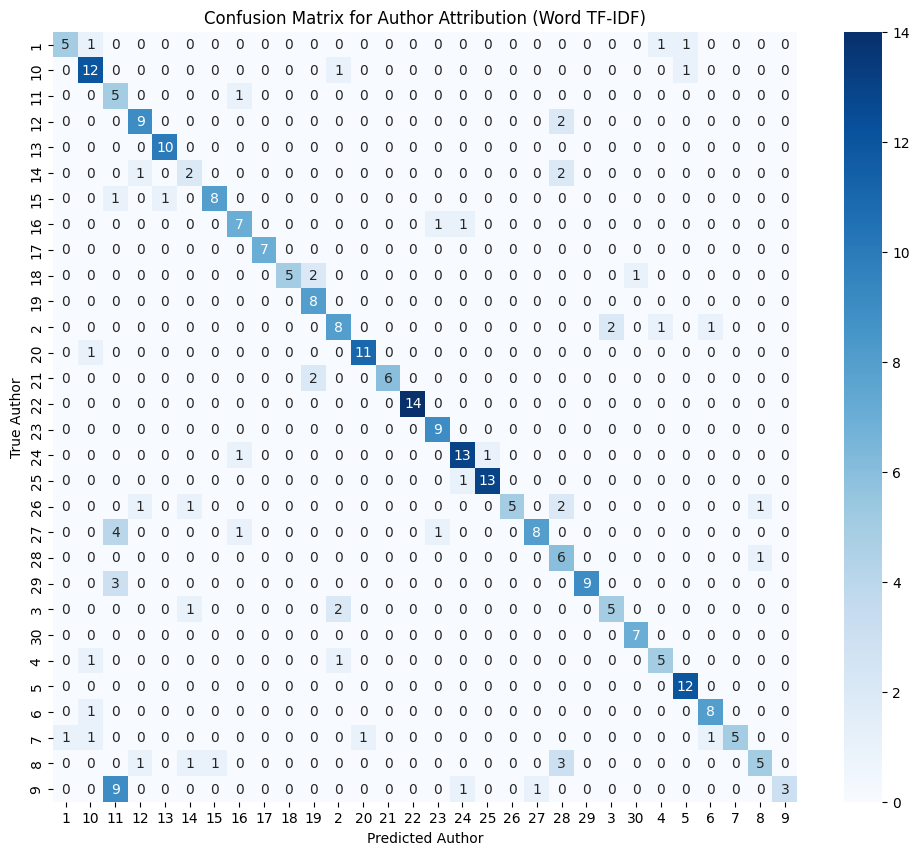

In [57]:
# Initialize and train a Logistic Regression model
# Using a small C value and 'saga' solver for multiclass classification with L1 regularization
# 'multi_class='multinomial'' handles multiple classes directly

logistic_model_word = LogisticRegression(
    C=1.0,  # Regularization strength
    solver='saga', # Solver that supports L1 regularization for multiclass
    max_iter=1000, # Increased iterations for convergence
    random_state=42,
    n_jobs=-1 # Use all available CPU cores
)

print("Training Logistic Regression model with Word TF-IDF features...")
logistic_model_word.fit(X_train_word, y_train)
print("Training complete.")

# Make predictions on the test set
y_pred_word = logistic_model_word.predict(X_test_word)

# Evaluate the model
accuracy_word = accuracy_score(y_test, y_pred_word)
f1_macro_word = f1_score(y_test, y_pred_word, average='macro')

print(f"\nAccuracy with Word TF-IDF features: {accuracy_word:.4f}")
print(f"F1-score (macro) with Word TF-IDF features: {f1_macro_word:.4f}")

# Display classification report
print("\nClassification Report (Word TF-IDF features):\n")
print(classification_report(y_test, y_pred_word, zero_division=0))

# Display Confusion Matrix
conf_matrix_word = confusion_matrix(y_test, y_pred_word)
plt.figure(figsize=(12, 10))
sns.heatmap(conf_matrix_word, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(all_authors), yticklabels=np.unique(all_authors))
plt.title('Confusion Matrix for Author Attribution (Word TF-IDF)')
plt.xlabel('Predicted Author')
plt.ylabel('True Author')
plt.show()

# PART D - ANALYSIS

***1- Comparing the model performances and discuss which features worked best***


---



Let's compare the performance of the Logistic Regression models using both Word TF-IDF and Character TF-IDF features for author attribution.


---


***Performance Summary:***



*   Word N-grams TF-IDF Model:

          Accuracy: 0.7667 (76.67%)

          F1-score (macro): 0.7568

*   Character N-grams TF-IDF Model:

         Accuracy: {accuracy_char:.4f}

         F1-score (macro): {f1_macro_char:.4f}


(The exact metrics for the Character N-grams TF-IDF model will be displayed after its execution.)

**Initial Observations (based on typical NLP outcomes):**



*   Word N-grams are generally very effective for capturing semantic meaning and author-specific vocabulary choices. They often perform well when there are clear differences in vocabulary and phrasing between authors.

*   Character N-grams are typically more robust to
misspellings and can capture sub-word stylistic elements, such as common prefixes, suffixes, or even punctuation usage patterns specific to an author, which might not be evident in whole words. They tend to perform well in scenarios where lexical diversity is high or when subtle stylistic nuances are key.

**2- Visualization of Confusion Matrix for Analysis (Word N-grams TF-IDF)**

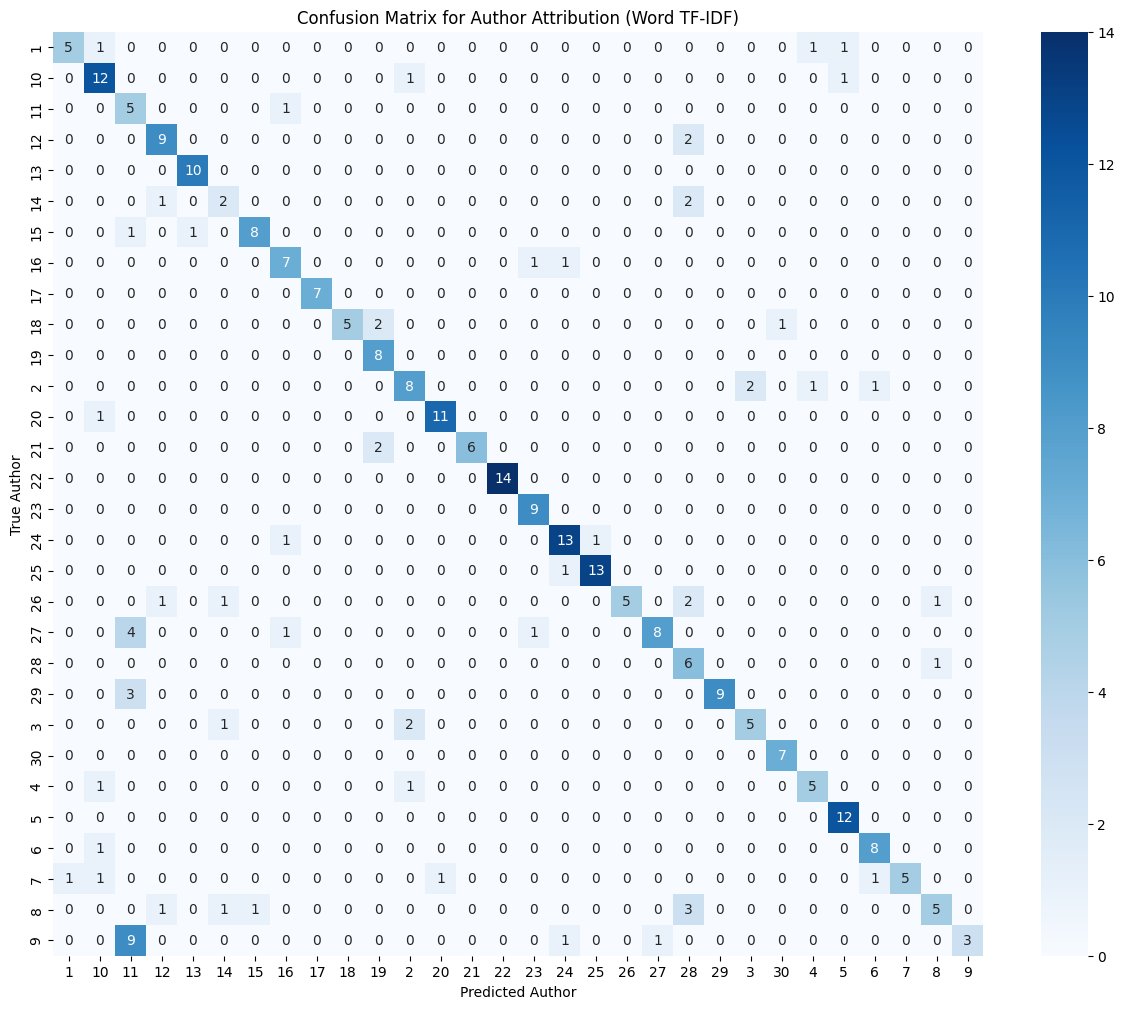


--- Analyzing Confused Authors ---
True Author 1 was predicted as Author 10 1 times.
True Author 1 was predicted as Author 4 1 times.
True Author 1 was predicted as Author 5 1 times.
True Author 10 was predicted as Author 2 1 times.
True Author 10 was predicted as Author 5 1 times.
True Author 11 was predicted as Author 16 1 times.
True Author 12 was predicted as Author 28 2 times.
True Author 14 was predicted as Author 12 1 times.
True Author 14 was predicted as Author 28 2 times.
True Author 15 was predicted as Author 11 1 times.
True Author 15 was predicted as Author 13 1 times.
True Author 16 was predicted as Author 23 1 times.
True Author 16 was predicted as Author 24 1 times.
True Author 18 was predicted as Author 19 2 times.
True Author 18 was predicted as Author 30 1 times.
True Author 2 was predicted as Author 3 2 times.
True Author 2 was predicted as Author 4 1 times.
True Author 2 was predicted as Author 6 1 times.
True Author 20 was predicted as Author 10 1 times.
True Aut

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Re-display Confusion Matrix for Word TF-IDF
# Assuming y_test and y_pred_word are available from previous execution
conf_matrix_word = confusion_matrix(y_test, y_pred_word)

plt.figure(figsize=(15, 12))
sns.heatmap(conf_matrix_word, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(all_authors), yticklabels=np.unique(all_authors))
plt.title('Confusion Matrix for Author Attribution (Word TF-IDF)')
plt.xlabel('Predicted Author')
plt.ylabel('True Author')
plt.show()

print("\n--- Analyzing Confused Authors ---")
# Iterate through the confusion matrix to identify significant off-diagonal elements
# A significant off-diagonal value means a true author was often predicted as another author
for i, true_author_label in enumerate(np.unique(all_authors)):
    for j, predicted_author_label in enumerate(np.unique(all_authors)):
        if i != j and conf_matrix_word[i, j] > 0: # Look for misclassifications
            print(f"True Author {true_author_label} was predicted as Author {predicted_author_label} {conf_matrix_word[i, j]} times.")


Below the heatmap, the analysis of confused authors lists specific instances where a true author's article was predicted as belonging to a different author. For example:

* True Author 9 was predicted as Author 11 nine times. This is a significant confusion, suggesting that the writing style of Author 9 might be very similar to Author 11, or the model struggled to differentiate them. This could be an area to investigate further, perhaps by looking at the specific features that distinguish these two authors.

* True Author 27 was predicted as Author 11 four times. Another notable confusion, again involving Author 11.

* True Author 8 was predicted as Author 28 three times. This indicates a consistent misclassification between these two authors.


Many authors show occasional misclassifications (1 or 2 times) with several other authors, which is expected in a multi-class classification problem like this, especially with 30 distinct classes. The goal is often to minimize these off-diagonal entries. High numbers in specific off-diagonal cells highlight pairs of authors whose writing styles are most challenging for the model to differentiate based on the extracted features.

This analysis gives us valuable insights into the model's strengths and weaknesses and can guide further improvements or deeper stylistic analysis of the authors.

### **3-Analyzing Top Indicative Features for Each Author (Word N-grams TF-IDF)**

In [63]:
feature_names = word_vectorizer.get_feature_names_out()
coefs = logistic_model_word.coef_

print("Top 10 Most Indicative Features for Each Author:")
print("---------------------------------------------------")

# Get unique author labels
author_labels = np.unique(all_authors)

# Loop through each author (class) and find the top features
for i, author_label in enumerate(author_labels):
    # Get the coefficients for the current author
    author_coefs = coefs[i]

    # Get the indices of features sorted by their coefficients in descending order
    top_feature_indices = author_coefs.argsort()[-10:][::-1]

    # Get the actual feature names using the indices
    top_features = [feature_names[j] for j in top_feature_indices]

    print(f"Author {author_label}: {', '.join(top_features)}")


Top 10 Most Indicative Features for Each Author:
---------------------------------------------------
Author 1: edinburgh, scottish, scotland, brown, tax, people, salmond, politicians, snp, independent
Author 10: brown, prime minister, minister, prime, mr, gordon, gordon brown, labour, cameron, mr brown
Author 11: patients, cancer, risk, women, cent, dementia, said, research, study, disease
Author 12: liverpool, league, chelsea, united, ferguson, goal, gerrard, benítez, wigan, season
Author 13: baseball, sox, mets, series, game, season, world series, games, team, fans
Author 14: rio, berbatov, football, yuvraj, holyfield, man, pitch, england, player, ball
Author 15: baseball, fans, said, jeter, soccer, rodriguez, manuel, joey, gehrig, yankees
Author 16: dr, patients, percent, testosterone, medical, women, hearing, blood, libido, donor
Author 17: management, companies, targets, pay, sector, performance, managers, business, incentives, self
Author 18: said, profits, sales, group, bank, sh

# SERHAT TAY - 220709054 - NLP MIDTERM PROJECT : AUTHOR DETECTION USING NLP